In [1]:
import pandas as pd

df = pd.read_csv(r'..\data\W158_select_nan_recode.csv')

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n

In [2]:
dep_var_list = [
    'CONF_a_W158_r',
    'CONF_b_W158_r',
    'CONF_c_W158_r',
    'CONF_d_W158_r',
    'CONF_e_W158_r',
    'CONF_i_W158_r',
    'CONF_j_W158_r'
    ]

print(dep_var_list)

['CONF_a_W158_r', 'CONF_b_W158_r', 'CONF_c_W158_r', 'CONF_d_W158_r', 'CONF_e_W158_r', 'CONF_i_W158_r', 'CONF_j_W158_r']


In [3]:
# Dependent variable labels
dep_labels = {
    'CONF_a_W158_r': 'Elected officials',
    'CONF_b_W158_r': 'Journalists',
    'CONF_c_W158_r': 'The military',
    'CONF_d_W158_r': 'Religious leaders',
    'CONF_e_W158_r': 'Business leaders',
    'CONF_i_W158_r': 'Public school principals',
    'CONF_j_W158_r': 'Police officers',
    }

print(dep_labels)

{'CONF_a_W158_r': 'Elected officials', 'CONF_b_W158_r': 'Journalists', 'CONF_c_W158_r': 'The military', 'CONF_d_W158_r': 'Religious leaders', 'CONF_e_W158_r': 'Business leaders', 'CONF_i_W158_r': 'Public school principals', 'CONF_j_W158_r': 'Police officers'}


In [4]:
# Imputation and Scaling

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df[dep_var_list])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

--- Comprehensive Cluster Evaluation Table ---
 K      Inertia  Silhouette  Calinski-Harabasz  Davies-Bouldin Min Cluster % Max Cluster %
 2 51378.995963    0.214733        2944.189180        1.707853         40.5%         59.5%
 3 43859.632769    0.187819        2546.352963        1.624296         30.2%         39.4%
 4 39799.147350    0.164914        2196.672068        1.672378         17.2%         29.1%
 5 37393.994931    0.153048        1907.463302        1.726209         12.5%         26.3%
 6 35623.249682    0.146654        1696.962209        1.804331         11.1%         23.2%
 7 34193.434109    0.140264        1539.926562        1.927936          6.2%         18.2%
 8 32660.281287    0.137596        1446.026995        1.805697          8.3%         16.7%
 9 31636.333334    0.141618        1344.865132        1.851709          8.7%         13.2%


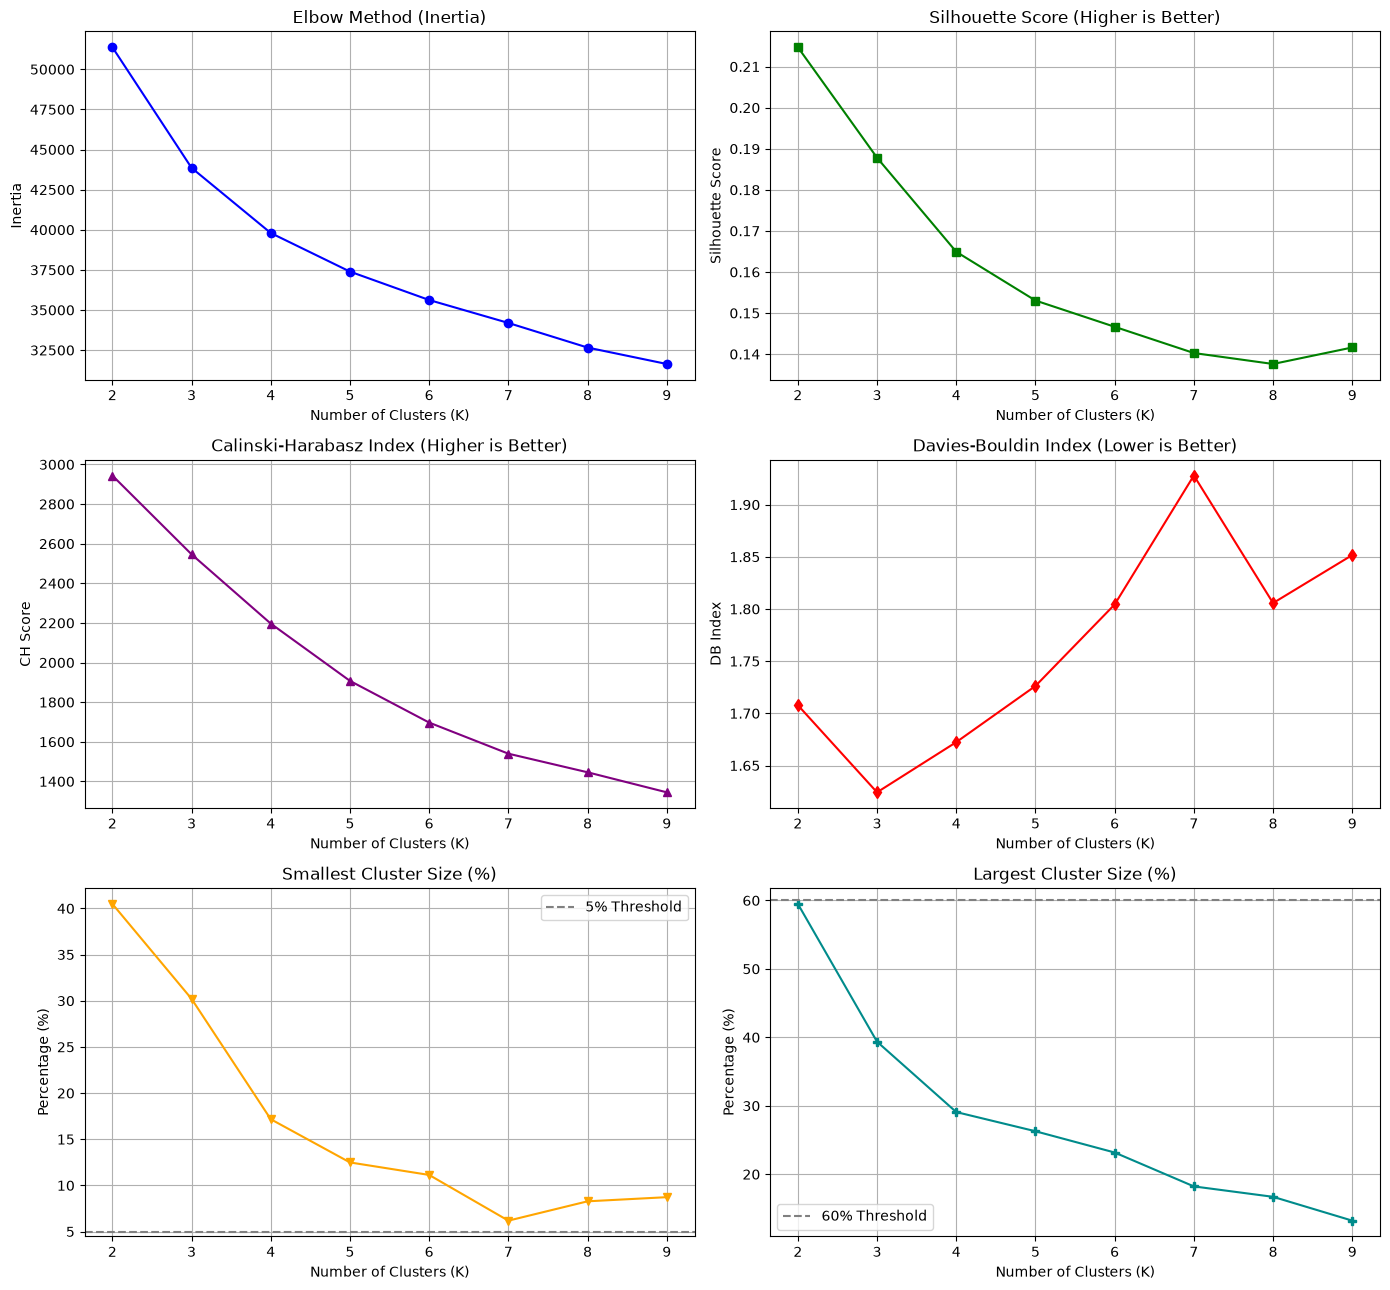

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)

# 1. Define range of K to test
k_range = range(2, 10)

inertia_list = []
silhouette_list = []
ch_score_list = []
db_score_list = []
min_cluster_pcts = []
max_cluster_pcts = []

# 2. Iterate through each K and calculate all metrics
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    # Calculate metrics
    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))
    ch_score_list.append(calinski_harabasz_score(X_scaled, labels))
    db_score_list.append(davies_bouldin_score(X_scaled, labels))

    # Cluster Size Proportions
    cluster_counts = pd.Series(labels).value_counts(normalize=True) * 100
    min_cluster_pcts.append(cluster_counts.min())
    max_cluster_pcts.append(cluster_counts.max())

# 3. Create comprehensive summary DataFrame
metrics_df = pd.DataFrame(
    {
        "K": list(k_range),
        "Inertia": inertia_list,
        "Silhouette": silhouette_list,
        "Calinski-Harabasz": ch_score_list,
        "Davies-Bouldin": db_score_list,
        "Min Cluster %": [f"{val:.1f}%" for val in min_cluster_pcts],
        "Max Cluster %": [f"{val:.1f}%" for val in max_cluster_pcts],
    }
)

print("--- Comprehensive Cluster Evaluation Table ---")
print(metrics_df.to_string(index=False))

# 4. Plot all six metrics in a 3x2 grid
fig, axes = plt.subplots(3, 2, figsize=(14, 13))

# Plot 1: Inertia (Elbow Method)
axes[0, 0].plot(k_range, inertia_list, marker="o", color="blue")
axes[0, 0].set_title("Elbow Method (Inertia)")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("Inertia")
axes[0, 0].grid(True)

# Plot 2: Silhouette Score
axes[0, 1].plot(k_range, silhouette_list, marker="s", color="green")
axes[0, 1].set_title("Silhouette Score (Higher is Better)")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].grid(True)

# Plot 3: Calinski-Harabasz Score
axes[1, 0].plot(k_range, ch_score_list, marker="^", color="purple")
axes[1, 0].set_title("Calinski-Harabasz Index (Higher is Better)")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("CH Score")
axes[1, 0].grid(True)

# Plot 4: Davies-Bouldin Index
axes[1, 1].plot(k_range, db_score_list, marker="d", color="red")
axes[1, 1].set_title("Davies-Bouldin Index (Lower is Better)")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("DB Index")
axes[1, 1].grid(True)

# Plot 5: Minimum Cluster Size (%)
axes[2, 0].plot(k_range, min_cluster_pcts, marker="v", color="orange")
axes[2, 0].axhline(y=5, color="gray", linestyle="--", label="5% Threshold")
axes[2, 0].set_title("Smallest Cluster Size (%)")
axes[2, 0].set_xlabel("Number of Clusters (K)")
axes[2, 0].set_ylabel("Percentage (%)")
axes[2, 0].grid(True)
axes[2, 0].legend()

# Plot 6: Maximum Cluster Size (%)
axes[2, 1].plot(k_range, max_cluster_pcts, marker="P", color="darkcyan")
axes[2, 1].axhline(y=60, color="gray", linestyle="--", label="60% Threshold")
axes[2, 1].set_title("Largest Cluster Size (%)")
axes[2, 1].set_xlabel("Number of Clusters (K)")
axes[2, 1].set_ylabel("Percentage (%)")
axes[2, 1].grid(True)
axes[2, 1].legend()

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
from sklearn.cluster import KMeans

# 1. Fit the K=4 model and save predictions
kmeans_k4 = KMeans(n_clusters=4, random_state=42, n_init=10)
df["Cluster_K4"] = kmeans_k4.fit_predict(X_scaled)

# 2. Fit the K=5 model and save predictions
kmeans_k5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster_K5"] = kmeans_k5.fit_predict(X_scaled)

# 3. Inspect the stored cluster columns alongside raw data
print(df[["Cluster_K4", "Cluster_K5"] + dep_var_list].head())

   Cluster_K4  Cluster_K5  CONF_a_W158_r  CONF_b_W158_r  CONF_c_W158_r  \
0           2           4            2.0            2.0            3.0   
1           1           2            2.0            3.0            4.0   
2           2           3            1.0            1.0            2.0   
3           1           2            3.0            3.0            4.0   
4           2           3            2.0            1.0            3.0   

   CONF_d_W158_r  CONF_e_W158_r  CONF_i_W158_r  CONF_j_W158_r  
0            2.0            3.0            3.0            4.0  
1            4.0            2.0            4.0            4.0  
2            3.0            2.0            3.0            3.0  
3            3.0            4.0            4.0            4.0  
4            3.0            2.0            2.0            3.0  


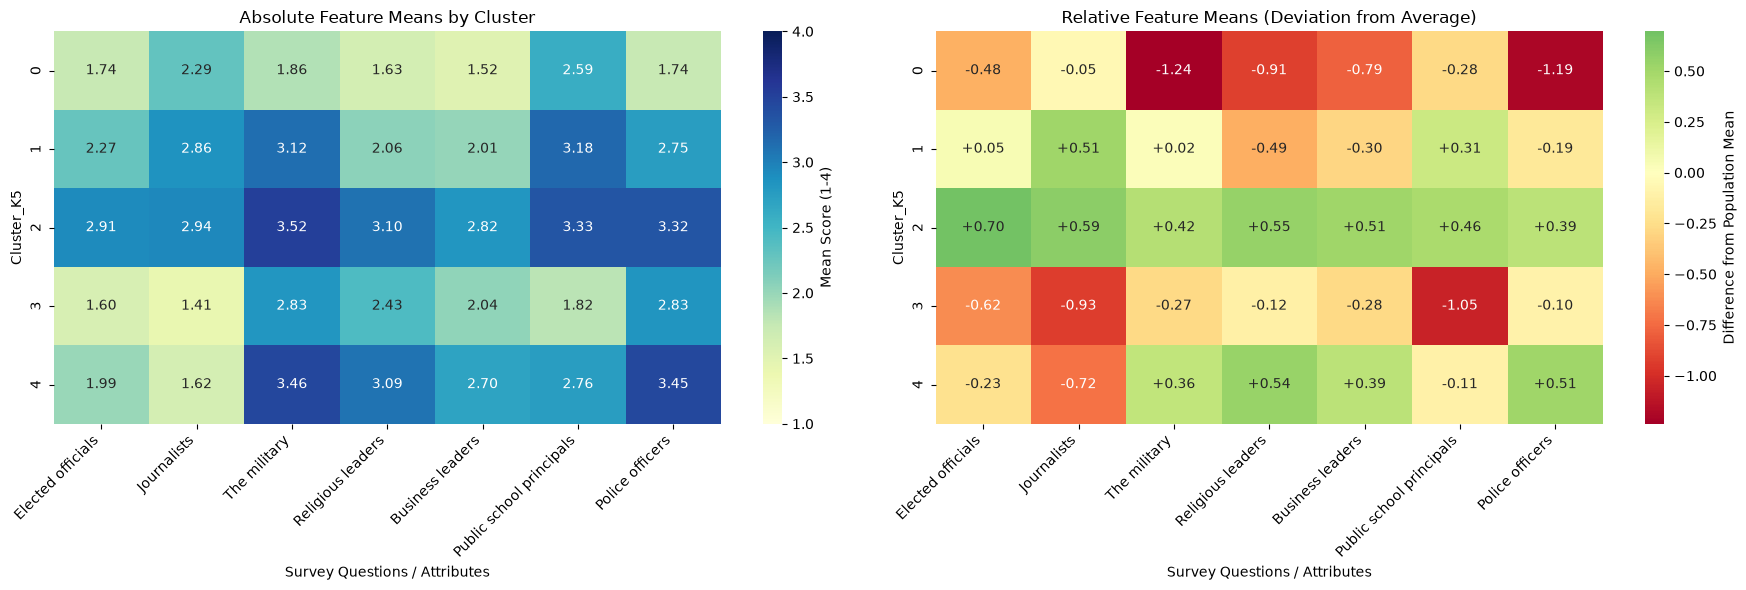

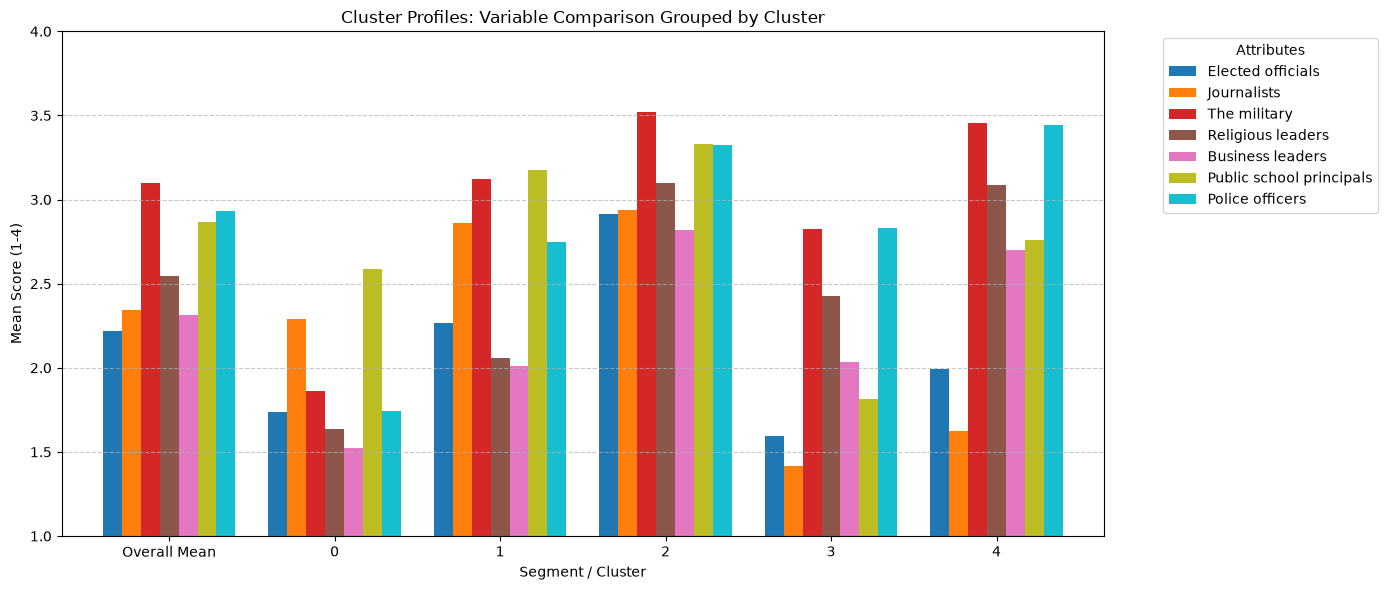

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cluster_var = "Cluster_K5"

# 1. Calculate Unscaled Baseline & Cluster Means
overall_mean = df[dep_var_list].mean().to_frame(name="Overall Mean").T
cluster_means = df.groupby(cluster_var)[dep_var_list].mean()

# 2. Rename columns using your dep_labels dictionary
cluster_means_labeled = cluster_means.rename(columns=dep_labels)
overall_mean_labeled = overall_mean.rename(columns=dep_labels)

# Calculate relative difference with labeled columns
relative_diff_labeled = cluster_means_labeled - overall_mean_labeled.iloc[0]

# Combine for the full profile table
profile_table_labeled = pd.concat([overall_mean_labeled, cluster_means_labeled])

# --- Visualizations ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Plot A: Absolute Means with Variable Labels
sns.heatmap(
    cluster_means_labeled,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=1,
    vmax=4,
    cbar_kws={"label": "Mean Score (1-4)"},
    ax=ax1,
)
ax1.set_title("Absolute Feature Means by Cluster")
ax1.set_xlabel("Survey Questions / Attributes")
ax1.set_ylabel(cluster_var)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right")

# Plot B: Relative Deviation with Variable Labels
sns.heatmap(
    relative_diff_labeled,
    annot=True,
    fmt="+.2f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Difference from Population Mean"},
    ax=ax2,
)
ax2.set_title("Relative Feature Means (Deviation from Average)")
ax2.set_xlabel("Survey Questions / Attributes")
ax2.set_ylabel(cluster_var)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

# --- Plot C: Labeled Profile Bar Plot ---

ax = profile_table_labeled.plot(
    kind="bar", figsize=(14, 6), colormap="tab10", width=0.8
)

plt.title("Cluster Profiles: Variable Comparison Grouped by Cluster")
plt.xlabel("Segment / Cluster")
plt.ylabel("Mean Score (1-4)")

# Position legend outside plot area for long variable labels
plt.legend(title="Attributes", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.ylim(1, 4)
plt.xticks(rotation=0)  # Keeps Cluster labels horizontal for easy reading
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

Look at your relative heatmap
Highlight variables where a cluster deviates from the population average by at least 0.30 to 0.50 points on a 4-point scale

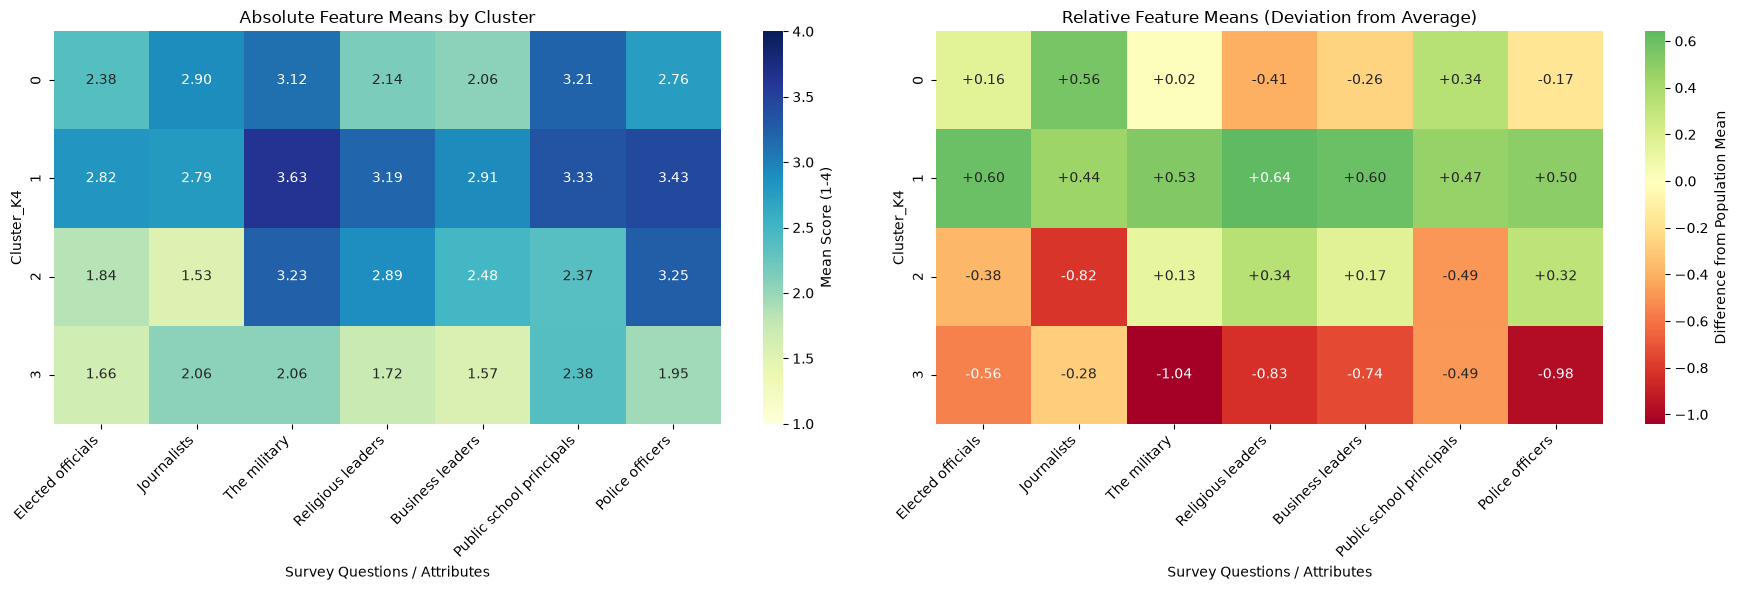

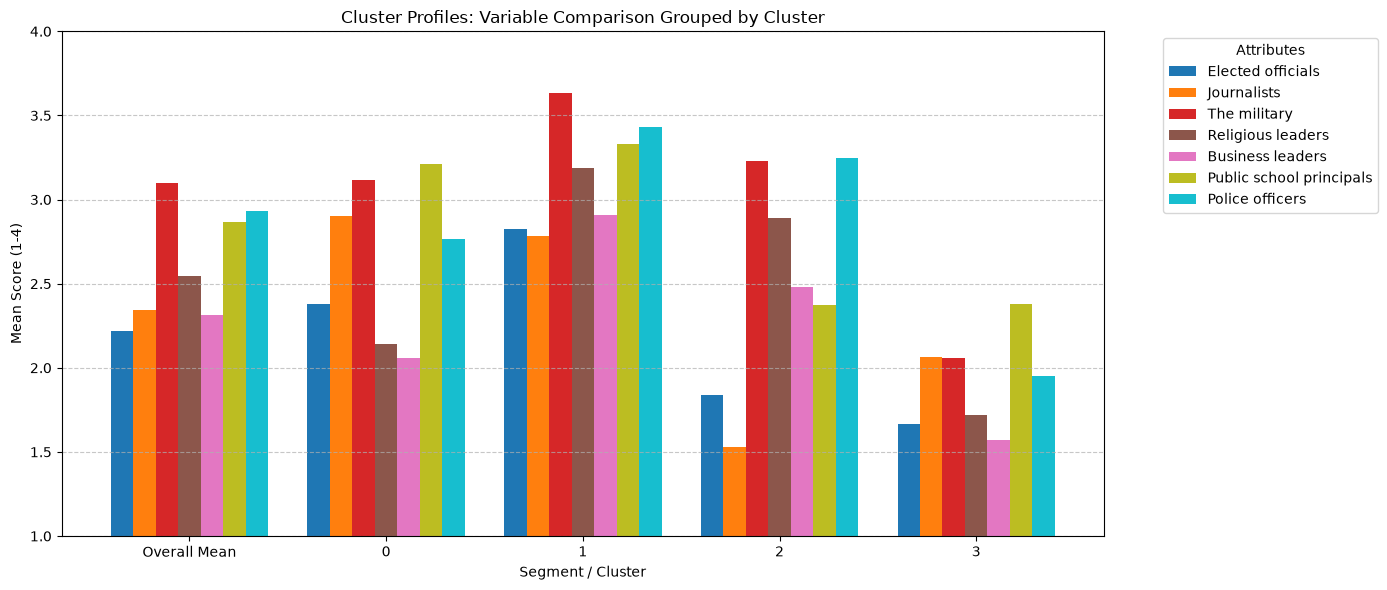

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cluster_var = "Cluster_K4"

# 1. Calculate Unscaled Baseline & Cluster Means
overall_mean = df[dep_var_list].mean().to_frame(name="Overall Mean").T
cluster_means = df.groupby(cluster_var)[dep_var_list].mean()

# 2. Rename columns using your dep_labels dictionary
cluster_means_labeled = cluster_means.rename(columns=dep_labels)
overall_mean_labeled = overall_mean.rename(columns=dep_labels)

# Calculate relative difference with labeled columns
relative_diff_labeled = cluster_means_labeled - overall_mean_labeled.iloc[0]

# Combine for the full profile table
profile_table_labeled = pd.concat([overall_mean_labeled, cluster_means_labeled])

# --- Visualizations ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Plot A: Absolute Means with Variable Labels
sns.heatmap(
    cluster_means_labeled,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=1,
    vmax=4,
    cbar_kws={"label": "Mean Score (1-4)"},
    ax=ax1,
)
ax1.set_title("Absolute Feature Means by Cluster")
ax1.set_xlabel("Survey Questions / Attributes")
ax1.set_ylabel(cluster_var)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right")

# Plot B: Relative Deviation with Variable Labels
sns.heatmap(
    relative_diff_labeled,
    annot=True,
    fmt="+.2f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Difference from Population Mean"},
    ax=ax2,
)
ax2.set_title("Relative Feature Means (Deviation from Average)")
ax2.set_xlabel("Survey Questions / Attributes")
ax2.set_ylabel(cluster_var)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

# --- Plot C: Labeled Profile Bar Plot ---

ax = profile_table_labeled.plot(
    kind="bar", figsize=(14, 6), colormap="tab10", width=0.8
)

plt.title("Cluster Profiles: Variable Comparison Grouped by Cluster")
plt.xlabel("Segment / Cluster")
plt.ylabel("Mean Score (1-4)")

# Position legend outside plot area for long variable labels
plt.legend(title="Attributes", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.ylim(1, 4)
plt.xticks(rotation=0)  # Keeps Cluster labels horizontal for easy reading
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [11]:
import pandas as pd

# Cross-tabulation showing counts of people in K=4 vs K=5
crosstab_counts = pd.crosstab(
    df["Cluster_K4"],
    df["Cluster_K5"],
    margins=True,
    margins_name="Total",
)

print("--- Person Counts: K=4 (Rows) vs K=5 (Columns) ---")
print(crosstab_counts)

--- Person Counts: K=4 (Rows) vs K=5 (Columns) ---
Cluster_K5     0     1     2     3     4  Total
Cluster_K4                                     
0             44  2378   348     8    12   2790
1              0     0  2169     0   309   2478
2              0    43     4   918  1713   2678
3           1154    85     0   408     0   1647
Total       1198  2506  2521  1334  2034   9593


In [12]:
crosstab_counts

Cluster_K5,0,1,2,3,4,Total
Cluster_K4,,,,,,
0,44,2378,348,8,12,2790
1,0,0,2169,0,309,2478
2,0,43,4,918,1713,2678
3,1154,85,0,408,0,1647
Total,1198,2506,2521,1334,2034,9593


After looking at the data, I think 5 is better than 4.

In [13]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

k = 5  
labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)

mask = labels != -1                      # always all True for kmeans; kept for parity with DBSCAN
n_clusters = len(set(labels[mask]))
sizes = np.bincount(labels[mask]) / len(labels) * 100   # % of total points

print(f"Clusters found:    {n_clusters}")
print(f"Noise fraction:    {(~mask).mean():.3f}")
print(f"Smallest cluster:  {sizes.min():.1f}% of total")
print(f"Largest cluster:   {sizes.max():.1f}% of total")
print(f"Silhouette:        {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Davies-Bouldin:    {davies_bouldin_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_scaled[mask], labels[mask]):.1f}")

Clusters found:    5
Noise fraction:    0.000
Smallest cluster:  12.5% of total
Largest cluster:   26.3% of total
Silhouette:        0.153
Davies-Bouldin:    1.726
Calinski-Harabasz: 1907.5


In [15]:
print("K-means solution")
print()
print(f"Clusters found:    {n_clusters}")
print(f"Noise fraction:    {(~mask).mean():.3f}")
print(f"Smallest cluster:  {sizes.min():.1f}% of total")
print(f"Largest cluster:   {sizes.max():.1f}% of total")
print(f"Silhouette:        {silhouette_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Davies-Bouldin:    {davies_bouldin_score(X_scaled[mask], labels[mask]):.3f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_scaled[mask], labels[mask]):.1f}")

K-means solution

Clusters found:    5
Noise fraction:    0.000
Smallest cluster:  12.5% of total
Largest cluster:   26.3% of total
Silhouette:        0.153
Davies-Bouldin:    1.726
Calinski-Harabasz: 1907.5


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9593 entries, 0 to 9592
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   QKEY                  9593 non-null   int64  
 1   F_METRO               9585 non-null   float64
 2   F_CREGION             9585 non-null   float64
 3   F_CDIVISION           9585 non-null   float64
 4   F_USR_SELFID          9493 non-null   float64
 5   F_AGECAT              9555 non-null   float64
 6   F_GENDER              9561 non-null   float64
 7   F_EDUCCAT             9572 non-null   float64
 8   F_EDUCCAT2            9572 non-null   float64
 9   F_HISP                9565 non-null   float64
 10  F_RACECMB             9449 non-null   float64
 11  F_RACETHNMOD          9491 non-null   float64
 12  F_BIRTHPLACE          9551 non-null   float64
 13  F_MARITAL             9548 non-null   float64
 14  F_RELIG               9536 non-null   float64
 15  F_PARTY_FINAL         9534 non-n